In [6]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

In [4]:
os.chdir("..")
print("Working dir:", os.getcwd())

Working dir: e:\cat&dog project


In [7]:
splits = ['train', 'val', 'test']
classes = ['cat', 'dog']

for split in splits:
    print(f"\n {split}/")
    for cls in classes:
        path = f"data/{split}/{cls}"
        count = len(os.listdir(path)) if os.path.exists(path) else 0
        print(f"   {cls}: {count} รูป")


 train/
   cat: 1500 รูป
   dog: 1501 รูป

 val/
   cat: 500 รูป
   dog: 500 รูป

 test/
   cat: 300 รูป
   dog: 300 รูป


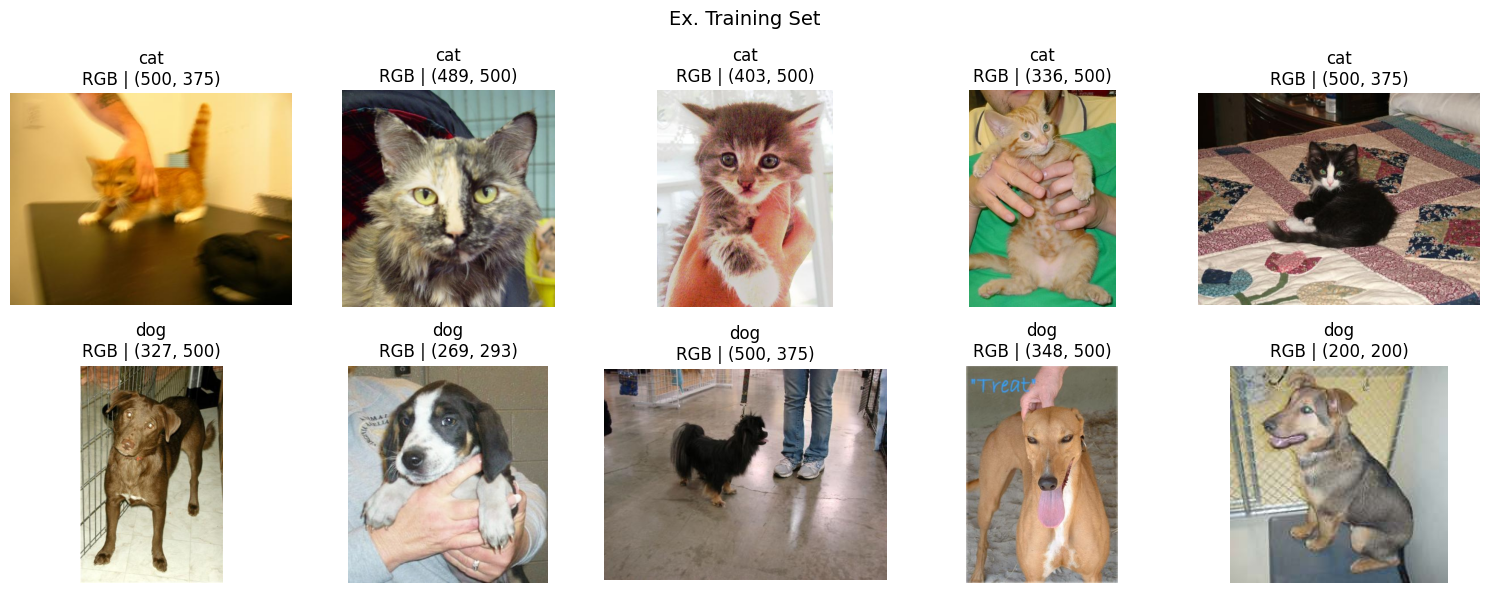

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Ex. Training Set", fontsize=14)

for row, cls in enumerate(classes):
    folder = f"data/train/{cls}"
    files = os.listdir(folder)[:5]
    for col, fname in enumerate(files):
        img = Image.open(os.path.join(folder, fname))
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{cls}\n{img.mode} | {img.size}")
        axes[row, col].axis('off')

plt.tight_layout()
plt.savefig("outputs/plots/sample_images.png")
plt.show()

In [11]:
non_rgb = []

for split in splits:
    for cls in classes:
        folder = f"data/{split}/{cls}"
        if not os.path.exists(folder):
            continue
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            try:
                img = Image.open(fpath)
                if img.mode != 'RGB':
                    non_rgb.append((fpath, img.mode))
            except Exception as e:
                print(f"Can't open: {fpath} — {e}")

if non_rgb:
    print(f"Number of non-RGB images {len(non_rgb)} รูป:")
    for path, mode in non_rgb[:10]: 
        print(f"   {mode} → {path}")
else:
    print("เป็น RGB ครบ")

Number of non-RGB images 9 รูป:
   P → data/train/cat\660.jpg
   P → data/train/cat\850.jpg
   P → data/train/cat\936.jpg
   P → data/train/dog\1259.jpg
   P → data/train/dog\1308.jpg
   CMYK → data/train/dog\1789.jpg
   P → data/train/dog\1866.jpg
   P → data/val/cat\140.jpg
   L → data/val/dog\1773.jpg
